Name: Kushi Niranjana

SRN: PES2UG24CS245

# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: The Pre-Publish Ethics Review

### Scenario

You're a junior analyst at **Northwind Retail Insights**. A colleague drafted a set of
charts for tomorrow's regional performance report, and your manager asked you to review
them before they go out. She's blunt about what she wants checked:

1. *"I can't tell what I'm supposed to look at first on any of these charts. There's no
   hierarchy."*
2. *"One of these charts will get someone using a grayscale office printer completely
   lost. Fix that before it ships."*
3. *"I saw a headline chart that made a tiny year-over-year change look like a crisis.
   Check the axis."*
4. *"Someone wrote 'this PROVES our new strategy is working' under a chart. That's not
   what a data label is for."*

You'll work through the same review a real analyst would: fix a hierarchy problem, make
a chart accessible, catch a scale exaggeration, and rewrite an overreaching annotation.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real sales data you'll be working with.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

sales = pd.read_csv("superstore.csv", encoding="latin-1")
sales["Order Date"] = pd.to_datetime(sales["Order Date"])
sales["Year"] = sales["Order Date"].dt.year

print(f"Loaded {len(sales):,} orders, {sales.Year.min()}-{sales.Year.max()}.")
sales[["Order Date", "Region", "Product Category", "Sales", "Profit"]].head()

Loaded 8,399 orders, 2009-2012.


,Order Date,Region,Product Category,Sales,Profit
0,2010-10-13,Nunavut,Office Supplies,261.5400,-213.25
1,2012-10-01,Nunavut,Office Supplies,10123.0200,457.81
2,2012-10-01,Nunavut,Office Supplies,244.5700,46.71
3,2011-07-10,Nunavut,Technology,4965.7595,1198.97
4,2010-08-28,Nunavut,Office Supplies,394.2700,30.94


## Task 1 — Fix the Missing Hierarchy (Complaint #1)

**Real-world usage:** The manager can't tell what to look at first on the current
chart.

**Why this technique:** Visual hierarchy (size + weight + color) creates an
unmistakable primary -> secondary -> tertiary reading order without needing
instructions.

**TODO:** Build a figure with 3 text elements, using ONLY `fontsize`, `fontweight`, and
`color` to create hierarchy:
1. **Primary:** the region with the highest total profit, in large bold colored text.
2. **Secondary:** one supporting sentence, medium size, muted color.
3. **Tertiary:** a data-source footnote, small, light gray.

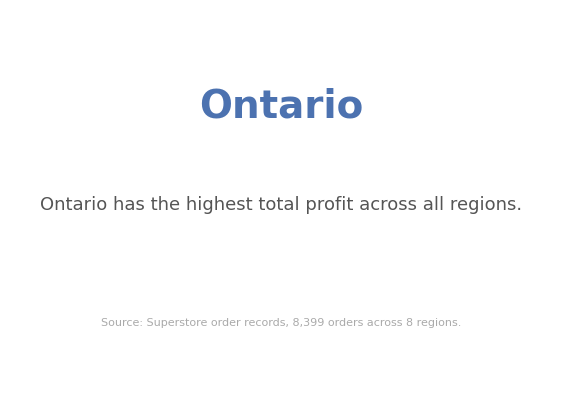

In [3]:
region_totals = sales.groupby("Region")["Profit"].sum().sort_values()
best_region = region_totals.idxmax()

fig, ax = plt.subplots(figsize=(7, 5))
ax.axis("off")

# TODO 1: primary element -- large, bold, colored


# TODO 2: secondary element -- medium, muted color


# TODO 3: tertiary element -- small, light gray


()# TODO 1: primary element -- large, bold, colored

ax.text(
    0.5,
    0.72,
    f"{best_region}",
    ha="center",
    fontsize=28,
    fontweight="bold",
    color="#4C72B0"
)


# TODO 2: secondary element -- medium, muted color

ax.text(
    0.5,
    0.48,
    f"{best_region} has the highest total profit across all regions.",
    ha="center",
    fontsize=13,
    color="#555555"
)


# TODO 3: tertiary element -- small, light gray

ax.text(
    0.5,
    0.18,
    "Source: Superstore order records, 8,399 orders across 8 regions.",
    ha="center",
    fontsize=8,
    color="#aaaaaa"
)

plt.show()

**Reflection:** Without reading any labels, in what order do your eyes land on the
three text elements? If someone glanced at this for only 2 seconds, what's the one
fact they'd walk away with?

_Your answer:_

My eyes land first on the large, bold, colored region name because it has the strongest visual weight. The supporting sentence comes second because it is smaller and muted, while the source note is least prominent because it is small and light gray. If someone looked at this for only two seconds, they would immediately understand which region has the highest total profit.

## Task 2 — Make the Chart Accessible (Complaint #2)

**Real-world usage:** A colorblind or grayscale-printer viewer needs to be able to read
this chart too.

**Why this technique:** Redundant coding (color + pattern/shape) survives both
colorblindness and grayscale printing; color alone does not.

**TODO:**
1. Build a bar chart of total `Sales` by `Product Category`, one color per category.
2. Add a DIFFERENT hatch pattern per bar (`hatch="//"`, `"xx"`, `".."`) on top of the
   color, so the categories stay distinguishable if color is stripped away.
3. Add a legend showing category name.

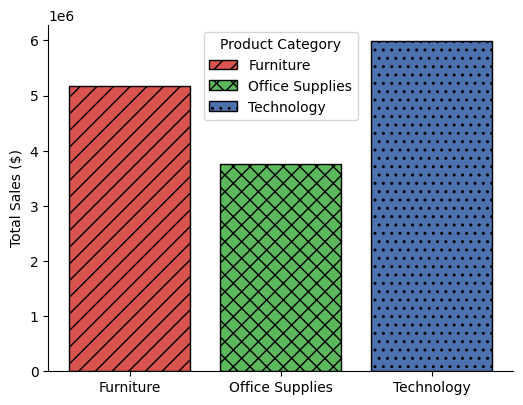

In [5]:
cat_sales = sales.groupby("Product Category")["Sales"].sum()

colors = {
    "Furniture": "#D9534F",
    "Office Supplies": "#5cb85c",
    "Technology": "#4C72B0"
}

hatches = {
    "Furniture": "//",
    "Office Supplies": "xx",
    "Technology": ".."
}

fig, ax = plt.subplots(figsize=(6, 4.5))

# TODO 1 & 2
for cat in cat_sales.index:
    ax.bar(
        cat,
        cat_sales[cat],
        color=colors[cat],
        hatch=hatches[cat],
        edgecolor="black",
        label=cat
    )

# TODO 3
ax.legend(
    title="Product Category"
)

ax.set_ylabel("Total Sales ($)")

plt.show()

**Reflection:** If you only used color (no hatch pattern), which two accessibility
failure modes from the lecture would this chart hit? Name both.

_Your answer:_
It would have two main accessibility problems. First, viewers with color-vision deficiencies may have difficulty distinguishing categories that rely only on color. Second, the categories could become difficult or impossible to distinguish when the chart is printed in grayscale because the color differences may disappear. Using both color and hatch patterns provides redundant coding and keeps the categories distinguishable.

## Task 3 — Catch the Axis Exaggeration (Complaint #3)

**Real-world usage:** A headline chart made a small real change look like a crisis.

**Why this technique:** Comparing the SAME data on a zero-baseline axis vs. a truncated
axis reveals exactly how much an axis choice is doing the "storytelling" instead of the
data.

**TODO:**
1. Compute total `Sales` by `Year`.
2. Compute the real percent change between the two most recent years.
3. Plot BOTH a zero-baseline version and a truncated-axis version, side by side, each
   titled with the real percent change.

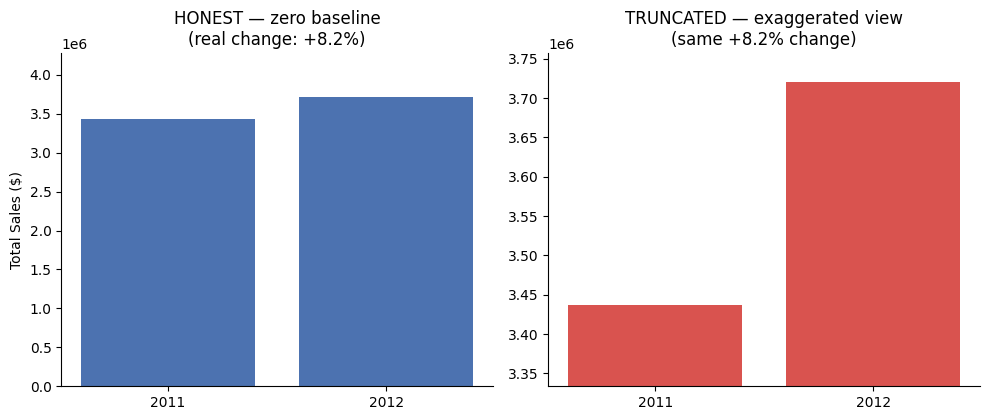

Real change from 2011 to 2012: +8.2%


In [6]:
yearly_sales = sales.groupby("Year")["Sales"].sum()

# TODO 1 & 2
y1, y2 = yearly_sales.index[-2], yearly_sales.index[-1]

v1 = yearly_sales[y1]
v2 = yearly_sales[y2]

pct_change = (v2 - v1) / v1 * 100

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4.3)
)

# TODO 3a: zero-baseline version
axes[0].bar(
    [str(y1), str(y2)],
    [v1, v2],
    color="#4C72B0"
)

axes[0].set_ylim(
    0,
    max(v1, v2) * 1.15
)

axes[0].set_title(
    f"HONEST — zero baseline\n(real change: {pct_change:+.1f}%)"
)

axes[0].set_ylabel("Total Sales ($)")


# TODO 3b: truncated-axis version
axes[1].bar(
    [str(y1), str(y2)],
    [v1, v2],
    color="#D9534F"
)

axes[1].set_ylim(
    min(v1, v2) * 0.97,
    max(v1, v2) * 1.01
)

axes[1].set_title(
    f"TRUNCATED — exaggerated view\n(same {pct_change:+.1f}% change)"
)

plt.tight_layout()
plt.show()

print(
    f"Real change from {y1} to {y2}: {pct_change:+.1f}%"
)

**Reflection:** Which of your two panels would you flag for the manager as
potentially misleading if it were used ALONE as the report's headline chart, with no
other context? Why?

_Your answer:_

The truncated-axis panel is the one I would flag as potentially misleading if it were used alone as the headline chart. Although the underlying sales values are exactly the same, starting the y-axis close to the two values makes the relatively small year-over-year change appear much larger than it really is. The zero-baseline version gives a more honest visual impression of the magnitude of the change. The actual percentage change should therefore always be considered together with the axis framing.

## Task 4 — Rewrite the Overreaching Annotation (Complaint #4)

**Real-world usage:** A colleague's annotation claimed a chart "PROVES" a strategy is
working — language the data alone cannot support.

**Why this technique:** Distinguishing descriptive / interpretive / persuasive
annotation lets you keep useful interpretation while cutting unsupported claims.

**TODO:**
1. Given the overreaching annotation text below, write a DESCRIPTIVE version (states
   only the fact) and an INTERPRETIVE version (explains a plausible, appropriately
   hedged reason) — no causal "PROVES" language in either.
2. Plot the yearly sales trend with your INTERPRETIVE annotation on the most recent
   data point.

ORIGINAL (persuasive, overreaching): This PROVES our new strategy is working -- scale it up immediately
DESCRIPTIVE: 2012 sales: $3,719,964
INTERPRETIVE: Sales increased by 8.2% from 2011 to 2012, which may indicate improvement in sales performance.


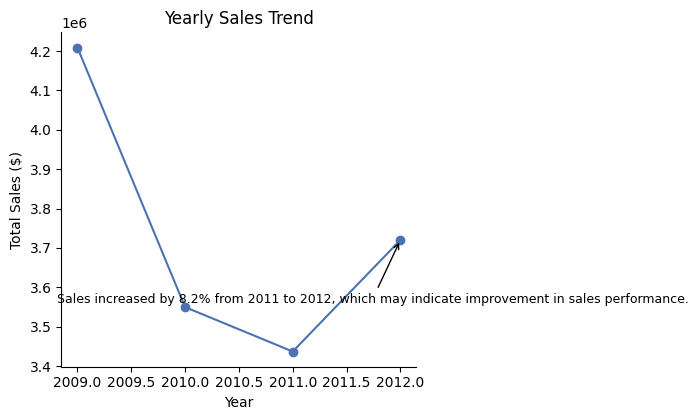

In [7]:
overreaching_original = "This PROVES our new strategy is working -- scale it up immediately"

# TODO 1: your rewrites

descriptive_version = (
    f"{y2} sales: ${yearly_sales.iloc[-1]:,.0f}"
)

interpretive_version = (
    f"Sales increased by {pct_change:.1f}% from {y1} to {y2}, "
    "which may indicate improvement in sales performance."
)

print(
    "ORIGINAL (persuasive, overreaching):",
    overreaching_original
)

print(
    "DESCRIPTIVE:",
    descriptive_version
)

print(
    "INTERPRETIVE:",
    interpretive_version
)


# TODO 2: plot with your interpretive annotation on the last data point

fig, ax = plt.subplots(
    figsize=(7, 4.3)
)

ax.plot(
    yearly_sales.index,
    yearly_sales.values,
    "o-",
    color="#4C72B0"
)

ax.annotate(
    interpretive_version,
    xy=(
        yearly_sales.index[-1],
        yearly_sales.iloc[-1]
    ),
    xytext=(-20, -45),
    textcoords="offset points",
    ha="center",
    fontsize=9,
    arrowprops=dict(
        arrowstyle="->"
    )
)

ax.set_xlabel("Year")
ax.set_ylabel("Total Sales ($)")
ax.set_title("Yearly Sales Trend")

plt.tight_layout()
plt.show()

**Reflection:** What specific evidence would you need (that this dataset alone
doesn't provide) before the ORIGINAL "proves it's working" claim would actually be
justified?

_Your answer:_

Before saying that the new strategy "proves" it is working, I would need evidence that isolates the effect of the strategy from other factors. For example, I would need information about when the strategy was introduced, comparable sales data from before and after the strategy, and ideally a control or comparison group that was not exposed to the strategy. I would also need to rule out other explanations such as seasonal effects, changes in pricing, promotions, market conditions, or changes in the number of customers. The current dataset only shows sales trends, so it cannot establish that the strategy caused the observed change.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence sign-off note to your manager summarizing
this review. Your answer should:
- State which ONE of the four fixes above you consider the most urgent to ship before
  tomorrow, and why.
- Reference the lecture's 5-question Ethical Visualization Audit — pick one question
  from it and explain how it applies to Task 3 or Task 4 specifically.
- Name one guardrail (a review step, a style-guide rule, etc.) you'd recommend
  permanently adding to the team's process to prevent these four issues recurring.

_Your final recommendation here:_

The most urgent fix to ship before tomorrow is the axis correction in Task 3 because a misleading scale can make a small real change appear to be a major crisis and could directly affect management decisions. For the Ethical Visualization Audit, I would apply Question 1: "Does the axis/scale choice honestly represent the magnitude of the difference?" This applies directly to Task 3 because the truncated axis changes the visual impression even though the underlying sales numbers remain unchanged. I would also apply Question 4 to Task 4 because annotation language must match what the data can actually support and should not make unsupported causal claims. As a permanent guardrail, I would recommend a pre-publication visualization checklist requiring an axis/scale check, accessibility check, and annotation-evidence check before any chart is included in an external report.